NAME: SAKSHAM BOLDHAN

CLASS : B2-B1-07

In [4]:
#Practical 3
import pandas as pd
import seaborn as sns

import matplotlib.pyplot as plt
#load a nuilt-in dataset
df=sns.load_dataset('tips')
print(df.head())

   total_bill   tip     sex smoker  day    time  size
0       16.99  1.01  Female     No  Sun  Dinner     2
1       10.34  1.66    Male     No  Sun  Dinner     3
2       21.01  3.50    Male     No  Sun  Dinner     3
3       23.68  3.31    Male     No  Sun  Dinner     2
4       24.59  3.61  Female     No  Sun  Dinner     4


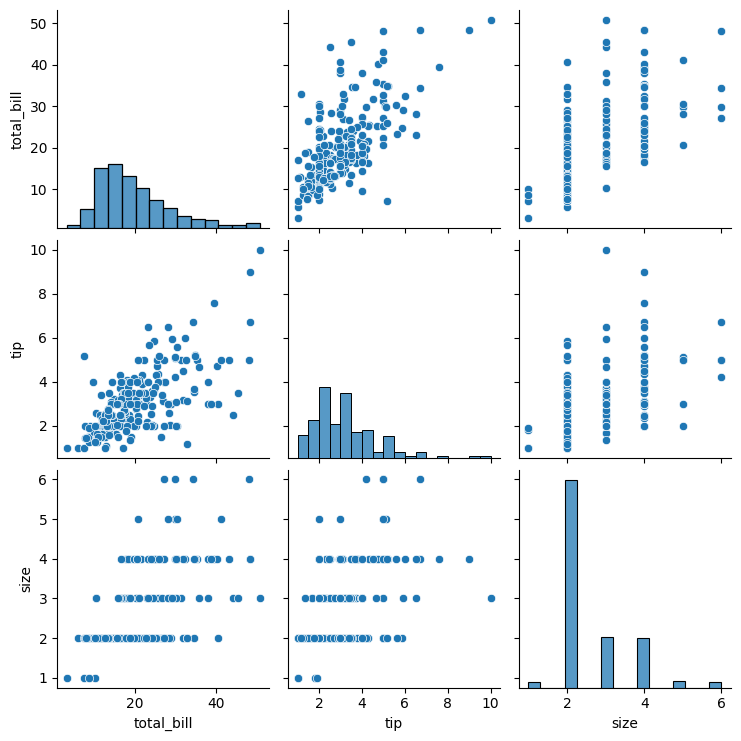

            total_bill       tip      size
total_bill    1.000000  0.675734  0.598315
tip           0.675734  1.000000  0.489299
size          0.598315  0.489299  1.000000


In [5]:
#create correlation matrix ,pair plots
mat=corr_matrix=df.corr(numeric_only=True)
pl=sns.pairplot(df)
plt.show()
print(mat)

In [7]:
import numpy as np
import pandas as pd

# 2. Set a random seed for reproducibility
np.random.seed(42)

# 3. Define the number of data points
num_samples = 1000

# 4. Generate data for 'SqFt' (between 800 and 3000 square feet)
SqFt = np.random.randint(800, 3001, num_samples)

# 5. Generate data for 'Age' (between 1 and 70 years)
Age = np.random.randint(1, 71, num_samples)

# 6. Generate data for 'Bedrooms' (1 to 5 bedrooms)
Bedrooms = np.random.randint(1, 6, num_samples)

# 7. Generate data for 'Location'
locations = ['Downtown', 'Suburban', 'Rural']
Location = np.random.choice(locations, num_samples)

# 8. Calculate 'Price' based on the generated features
# Base price formula: (SqFt * 150) + (Bedrooms * 50000) - (Age * 2000)
# Add random noise: np.random.normal(0, 50000, num_samples)
# Adjust for location

price_base = (SqFt * 150) + (Bedrooms * 50000) - (Age * 2000)

# Location adjustments
location_adjustment = {
    'Downtown': 100000,
    'Suburban': 50000,
    'Rural': -20000
}

Price = price_base + np.array([location_adjustment[loc] for loc in Location]) + np.random.normal(0, 50000, num_samples)

# Ensure prices are not negative
Price[Price < 0] = 0

# 9. Create a Pandas DataFrame
df_houses = pd.DataFrame({
    'SqFt': SqFt,
    'Age': Age,
    'Bedrooms': Bedrooms,
    'Location': Location,
    'Price': Price.astype(int) # Convert price to integer for cleaner display
})

# 10. Display the first few rows of the DataFrame
print(df_houses.head())


   SqFt  Age  Bedrooms  Location   Price
0  1660   22         2  Downtown  339037
1  2094    4         2  Suburban  445950
2  1930   26         5     Rural  427498
3  1895   58         4  Downtown  465073
4  2438   29         4  Downtown  669571


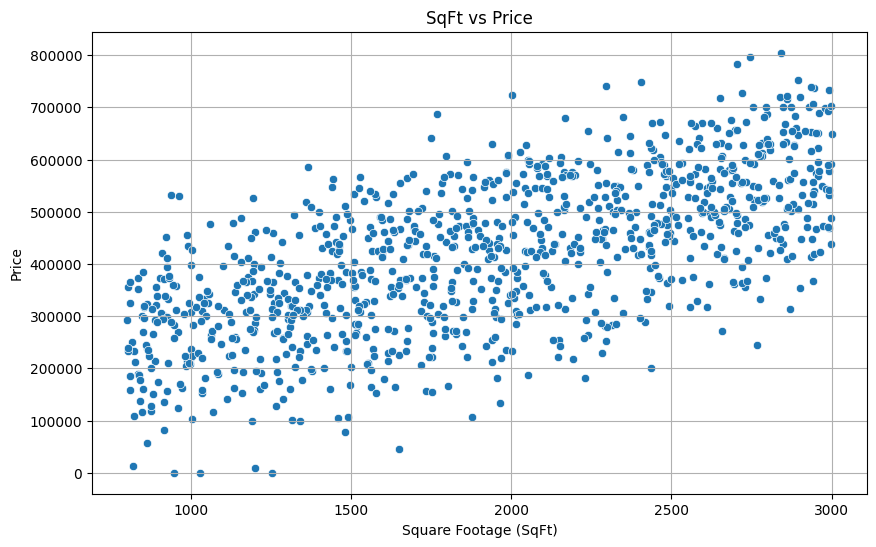

In [8]:
#Part A: Bivariate Exploration (2 Variables)
#Question: Does a larger house always cost more, or does the age of the house "pull" the price down?
      #Action: Create a scatter plot of SqFt vs Price.
plt.figure(figsize=(10, 6))
sns.scatterplot(x='SqFt', y='Price', data=df_houses)
plt.title('SqFt vs Price')
plt.xlabel('Square Footage (SqFt)')
plt.ylabel('Price')
plt.grid(True)
plt.show()

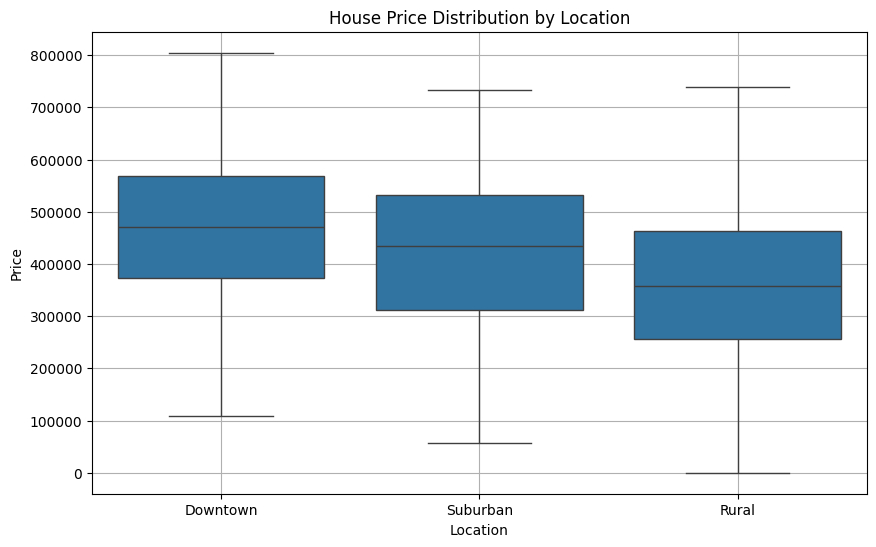

In [9]:
# Action: Create a box plot comparing Location vs Price.
plt.figure(figsize=(10, 6))
sns.boxplot(x='Location', y='Price', data=df_houses)
plt.title('House Price Distribution by Location')
plt.xlabel('Location')
plt.ylabel('Price')
plt.grid(True)
plt.show()

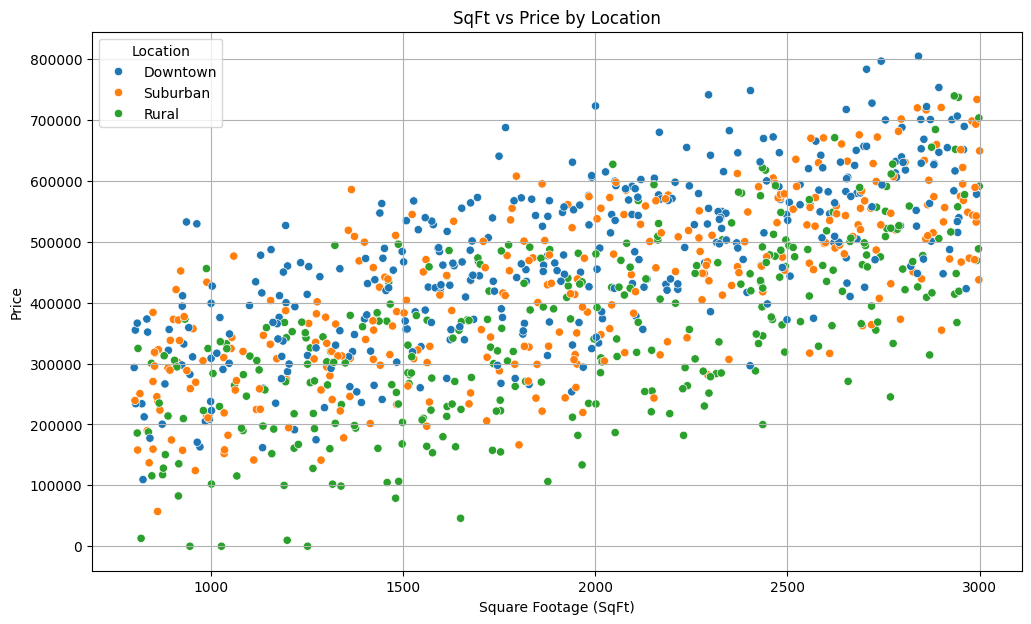

In [10]:
# Action: Create a scatter plot of SqFt vs Price, but use the hue parameter to color the points by Location.
plt.figure(figsize=(12, 7))
sns.scatterplot(x='SqFt', y='Price', hue='Location', data=df_houses)
plt.title('SqFt vs Price by Location')
plt.xlabel('Square Footage (SqFt)')
plt.ylabel('Price')
plt.grid(True)
plt.show()

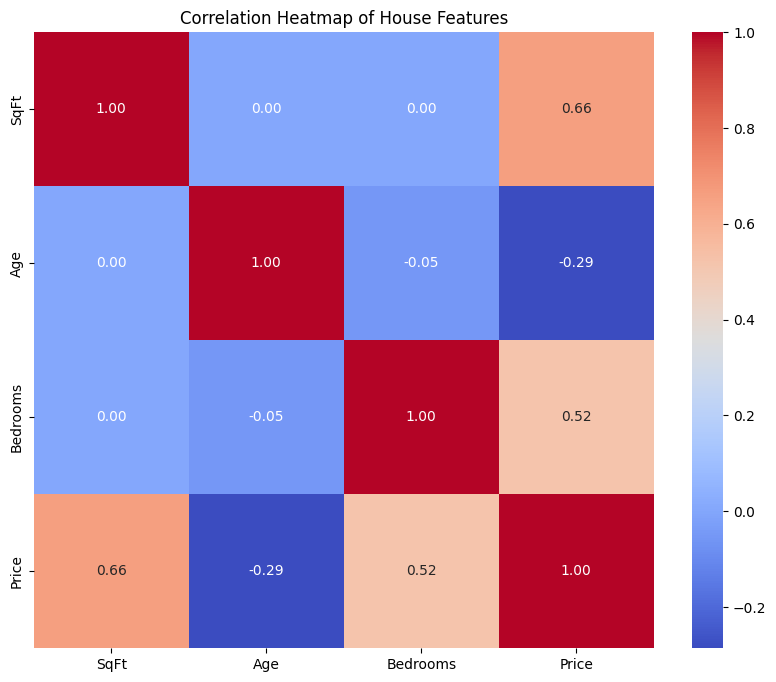

In [11]:
#Part C: Correlation Heatmap
 #Question: Which variable has the strongest absolute correlation with Price?
  #  Action: Generate a heatmap of the correlation matrix. (Note: You must exclude the categorical Location column or encode it).
numerical_cols = df_houses.select_dtypes(include=np.number)
correlation_matrix = numerical_cols.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap of House Features')
plt.show()